# 03.5 — Final 2-Speaker Re-ID / Track Assignment

Notebook นี้แก้ผล clustering จากขั้นก่อนหน้าให้เหลือ **2 speaker หลัก** ที่สะอาดขึ้น

จาก QA:
- Preliminary `Person 0` = Speaker 0
- Preliminary `Person 1` = Speaker 1
- Preliminary `Person 2` ≈ Speaker 0
- Preliminary `Person 3` ≈ Speaker 1
- Preliminary `Person 4` มี track ปนกัน จึงต้องแยกระดับ `track_id`

แนวคิด:
1. ใช้ track embeddings ที่มีอยู่แล้ว
2. สร้าง prototype ของ Speaker 0 จาก persons 0 + 2
3. สร้าง prototype ของ Speaker 1 จาก persons 1 + 3
4. เทียบทุก track กับ prototype ทั้งสองด้วย cosine similarity
5. track ที่มั่นใจสูง → AUTO
6. track ที่ใกล้กันมาก → REVIEW
7. เพิ่ม `speaker_id` กลับเข้า detection CSV เดิม

**ไม่ต้องรัน YOLO ใหม่ และไม่ต้องสร้าง embedding ใหม่**

## Cell 1 — Path

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r"D:\Face_detection")
VIDEO_ID = "video001"

REID_ROOT = PROJECT_ROOT / "dataset" / "reid" / VIDEO_ID

TRACK_EMB_NPY = REID_ROOT / "track_embeddings.npy"
TRACK_EMB_INDEX_CSV = REID_ROOT / "track_embedding_index.csv"
TRACK_PERSON_MAP_CSV = REID_ROOT / "track_person_map.csv"
REID_DETECTION_CSV = REID_ROOT / "reidentified_detection.csv"

OUTPUT_ROOT = REID_ROOT / "final_2speaker"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

for p in [TRACK_EMB_NPY, TRACK_EMB_INDEX_CSV, TRACK_PERSON_MAP_CSV, REID_DETECTION_CSV]:
    print(p, "->", p.exists())
    if not p.exists():
        raise FileNotFoundError(p)

D:\Face_detection\dataset\reid\video001\track_embeddings.npy -> True
D:\Face_detection\dataset\reid\video001\track_embedding_index.csv -> True
D:\Face_detection\dataset\reid\video001\track_person_map.csv -> True
D:\Face_detection\dataset\reid\video001\reidentified_detection.csv -> True


## Cell 2 — โหลดข้อมูล

In [2]:
track_embeddings = np.load(TRACK_EMB_NPY)
track_embedding_df = pd.read_csv(TRACK_EMB_INDEX_CSV)
track_person_df = pd.read_csv(TRACK_PERSON_MAP_CSV)
reid_df = pd.read_csv(REID_DETECTION_CSV)

track_embedding_df["track_id"] = track_embedding_df["track_id"].astype(int)
track_embedding_df["track_embedding_index"] = track_embedding_df["track_embedding_index"].astype(int)

track_person_df["track_id"] = track_person_df["track_id"].astype(int)
track_person_df["person_id"] = track_person_df["person_id"].astype(int)

print("Track embeddings:", track_embeddings.shape)
print("Tracks indexed   :", len(track_embedding_df))
print("Prelim persons   :", sorted(track_person_df["person_id"].unique().tolist()))
print("Detection rows   :", len(reid_df))

Track embeddings: (251, 512)
Tracks indexed   : 251
Prelim persons   : [0, 1, 2, 3, 4]
Detection rows   : 256620


## Cell 3 — Seed groups

In [3]:
SPEAKER0_SEED_PERSONS = [0, 2]
SPEAKER1_SEED_PERSONS = [1, 3]

print("Speaker 0 seed persons:", SPEAKER0_SEED_PERSONS)
print("Speaker 1 seed persons:", SPEAKER1_SEED_PERSONS)

Speaker 0 seed persons: [0, 2]
Speaker 1 seed persons: [1, 3]


## Cell 4 — Helpers

In [4]:
def get_track_embedding(track_id):
    row = track_embedding_df[
        track_embedding_df["track_id"] == int(track_id)
    ]

    if len(row) != 1:
        return None

    idx = int(row.iloc[0]["track_embedding_index"])
    emb = np.asarray(track_embeddings[idx], dtype=np.float32)

    norm = np.linalg.norm(emb)
    if norm > 0:
        emb = emb / norm

    return emb


def cosine_similarity(a, b):
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    na = np.linalg.norm(a)
    nb = np.linalg.norm(b)

    if na == 0 or nb == 0:
        return np.nan

    return float(np.dot(a, b) / (na * nb))

print("Helpers ready")

Helpers ready


## Cell 5 — สร้าง speaker prototypes

In [5]:
def build_prototype(person_ids):
    track_ids = (
        track_person_df[
            track_person_df["person_id"].isin(person_ids)
        ]["track_id"]
        .astype(int)
        .tolist()
    )

    embs = []

    for tid in track_ids:
        emb = get_track_embedding(tid)
        if emb is not None:
            embs.append(emb)

    if not embs:
        raise RuntimeError(f"No embeddings for seed persons: {person_ids}")

    prototype = np.mean(np.stack(embs), axis=0)

    norm = np.linalg.norm(prototype)
    if norm > 0:
        prototype = prototype / norm

    return prototype.astype(np.float32), track_ids


speaker0_proto, speaker0_seed_tracks = build_prototype(SPEAKER0_SEED_PERSONS)
speaker1_proto, speaker1_seed_tracks = build_prototype(SPEAKER1_SEED_PERSONS)

print("Speaker 0 seed tracks:", len(speaker0_seed_tracks))
print("Speaker 1 seed tracks:", len(speaker1_seed_tracks))
print("Prototype similarity:", cosine_similarity(speaker0_proto, speaker1_proto))

Speaker 0 seed tracks: 117
Speaker 1 seed tracks: 129
Prototype similarity: 0.06763068586587906


## Cell 6 — เทียบทุก track กับ 2 prototypes

In [6]:
assignment_rows = []

all_track_ids = sorted(
    track_embedding_df["track_id"].astype(int).unique().tolist()
)

for tid in all_track_ids:
    emb = get_track_embedding(tid)

    if emb is None:
        continue

    sim0 = cosine_similarity(emb, speaker0_proto)
    sim1 = cosine_similarity(emb, speaker1_proto)

    if sim0 >= sim1:
        candidate = 0
        best_sim = sim0
        second_sim = sim1
    else:
        candidate = 1
        best_sim = sim1
        second_sim = sim0

    margin = best_sim - second_sim

    assignment_rows.append({
        "track_id": int(tid),
        "sim_speaker0": round(sim0, 6),
        "sim_speaker1": round(sim1, 6),
        "candidate_speaker_id": int(candidate),
        "best_similarity": round(best_sim, 6),
        "second_similarity": round(second_sim, 6),
        "similarity_margin": round(margin, 6),
    })

assignment_df = pd.DataFrame(assignment_rows)

display(
    assignment_df.sort_values("similarity_margin").head(30)
)

,track_id,sim_speaker0,sim_speaker1,candidate_speaker_id,best_similarity,second_similarity,similarity_margin
248,253,0.636848,0.601794,0,0.636848,0.601794,0.035054
6,6,0.567219,0.646298,1,0.646298,0.567219,0.079079
242,247,0.588971,0.693933,1,0.693933,0.588971,0.104962
14,14,0.609164,0.720290,1,0.720290,0.609164,0.111126
178,183,0.632915,0.211388,0,0.632915,0.211388,0.421526
155,160,0.659255,0.217947,0,0.659255,0.217947,0.441308
154,159,0.598330,0.138063,0,0.598330,0.138063,0.460268
245,250,0.373506,0.846730,1,0.846730,0.373506,0.473224
95,100,0.884076,0.364613,0,0.884076,0.364613,0.519462
163,168,0.890869,0.360580,0,0.890869,0.360580,0.530290


## Cell 7 — เพิ่ม preliminary person / stats

In [7]:
extra_cols = [
    "track_id", "person_id", "detections",
    "first_frame", "last_frame", "mean_x1", "mean_conf"
]

available_cols = [
    c for c in extra_cols
    if c in track_person_df.columns
]

assignment_df = assignment_df.merge(
    track_person_df[available_cols],
    on="track_id",
    how="left"
)

display(
    assignment_df.sort_values("similarity_margin").head(50)
)

,track_id,sim_speaker0,sim_speaker1,candidate_speaker_id,best_similarity,second_similarity,similarity_margin,person_id,detections,first_frame,last_frame,mean_x1,mean_conf
248,253,0.636848,0.601794,0,0.636848,0.601794,0.035054,4,184,178044,178227,868.694717,0.823211
6,6,0.567219,0.646298,1,0.646298,0.567219,0.079079,4,81,645,725,888.497272,0.818127
242,247,0.588971,0.693933,1,0.693933,0.588971,0.104962,4,275,177049,177323,865.365436,0.827884
14,14,0.609164,0.720290,1,0.720290,0.609164,0.111126,4,2444,2025,4468,879.044782,0.818746
178,183,0.632915,0.211388,0,0.632915,0.211388,0.421526,2,13,145442,145454,476.278308,0.595410
155,160,0.659255,0.217947,0,0.659255,0.217947,0.441308,2,24,123236,123260,469.661625,0.427350
154,159,0.598330,0.138063,0,0.598330,0.138063,0.460268,2,5,123217,123222,467.681600,0.510470
245,250,0.373506,0.846730,1,0.846730,0.373506,0.473224,4,478,177378,177855,873.289992,0.824709
95,100,0.884076,0.364613,0,0.884076,0.364613,0.519462,0,192,68435,68626,846.210651,0.827053
163,168,0.890869,0.360580,0,0.890869,0.360580,0.530290,0,559,136673,137231,833.828948,0.824530


## Cell 8 — AUTO / REVIEW threshold

In [8]:
MIN_BEST_SIMILARITY = 0.30
MIN_MARGIN = 0.08

def assign_status(row):
    if row["best_similarity"] < MIN_BEST_SIMILARITY:
        return "REVIEW"

    if row["similarity_margin"] < MIN_MARGIN:
        return "REVIEW"

    return "AUTO"

assignment_df["status"] = assignment_df.apply(
    assign_status,
    axis=1
)

print(assignment_df["status"].value_counts())

print("\nCandidate speaker counts:")
print(
    assignment_df[
        assignment_df["status"] == "AUTO"
    ]["candidate_speaker_id"].value_counts()
)

status
AUTO      249
REVIEW      2
Name: count, dtype: int64

Candidate speaker counts:
candidate_speaker_id
1    132
0    117
Name: count, dtype: int64


## Cell 9 — ตรวจ preliminary Person 4

In [9]:
person4_check = assignment_df[
    assignment_df["person_id"] == 4
].copy()

display(
    person4_check[
        [
            "track_id",
            "detections",
            "first_frame",
            "last_frame",
            "mean_x1",
            "sim_speaker0",
            "sim_speaker1",
            "similarity_margin",
            "candidate_speaker_id",
            "status",
        ]
    ].sort_values("first_frame")
)

,track_id,detections,first_frame,last_frame,mean_x1,sim_speaker0,sim_speaker1,similarity_margin,candidate_speaker_id,status
6,6,81,645,725,888.497272,0.567219,0.646298,0.079079,1,REVIEW
14,14,2444,2025,4468,879.044782,0.609164,0.720290,0.111126,1,AUTO
242,247,275,177049,177323,865.365436,0.588971,0.693933,0.104962,1,AUTO
245,250,478,177378,177855,873.289992,0.373506,0.846730,0.473224,1,AUTO
248,253,184,178044,178227,868.694717,0.636848,0.601794,0.035054,0,REVIEW


## Cell 10 — Final speaker map

In [10]:
final_map_df = assignment_df.copy()

final_map_df["speaker_id"] = np.where(
    final_map_df["status"] == "AUTO",
    final_map_df["candidate_speaker_id"],
    np.nan
)

display(
    final_map_df[
        [
            "track_id",
            "person_id",
            "candidate_speaker_id",
            "speaker_id",
            "sim_speaker0",
            "sim_speaker1",
            "similarity_margin",
            "status",
        ]
    ].head(50)
)

,track_id,person_id,candidate_speaker_id,speaker_id,sim_speaker0,sim_speaker1,similarity_margin,status
0,0,0,0,0.0,0.945137,0.047797,0.897340,AUTO
1,1,1,1,1.0,0.035063,0.878107,0.843044,AUTO
2,2,2,0,0.0,0.713712,0.013134,0.700578,AUTO
3,3,3,1,1.0,0.052411,0.718437,0.666026,AUTO
4,4,0,0,0.0,0.898336,0.062244,0.836092,AUTO
5,5,1,1,1.0,0.100086,0.798998,0.698912,AUTO
6,6,4,1,NaN,0.567219,0.646298,0.079079,REVIEW
7,7,0,0,0.0,0.932964,0.033322,0.899642,AUTO
8,8,1,1,1.0,0.066514,0.871266,0.804751,AUTO
9,9,0,0,0.0,0.949175,0.008832,0.940343,AUTO


## Cell 11 — QA summary

In [11]:
qa_summary = (
    final_map_df
    .groupby(["status", "candidate_speaker_id"])
    .agg(
        tracks=("track_id", "count"),
        detections=("detections", "sum"),
        mean_margin=("similarity_margin", "mean"),
        mean_best_similarity=("best_similarity", "mean"),
    )
    .reset_index()
)

display(qa_summary)

auto_detection_total = (
    final_map_df[
        final_map_df["status"] == "AUTO"
    ]["detections"].sum()
)

all_detection_total = final_map_df["detections"].sum()

print(
    "AUTO detection coverage:",
    f"{auto_detection_total / all_detection_total:.2%}"
)

,status,candidate_speaker_id,tracks,detections,mean_margin,mean_best_similarity
0,AUTO,0,117,118277,0.848347,0.909883
1,AUTO,1,132,137875,0.829474,0.901169
2,REVIEW,0,1,184,0.035054,0.636848
3,REVIEW,1,1,81,0.079079,0.646298


AUTO detection coverage: 99.90%


## Cell 12 — Preview REVIEW tracks

REVIEW tracks: [6, 253]

Track 6 | candidate=1 | sim0=0.567 | sim1=0.646 | margin=0.079


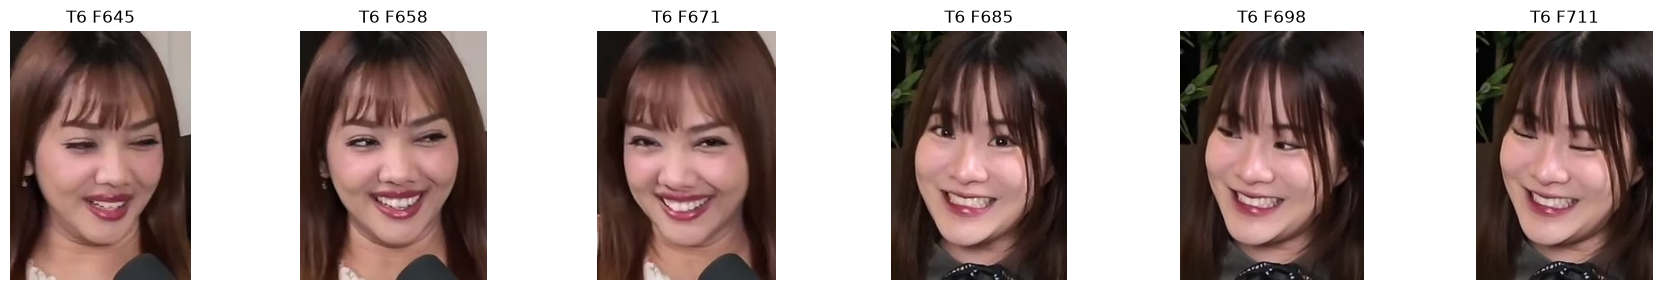


Track 253 | candidate=0 | sim0=0.637 | sim1=0.602 | margin=0.035


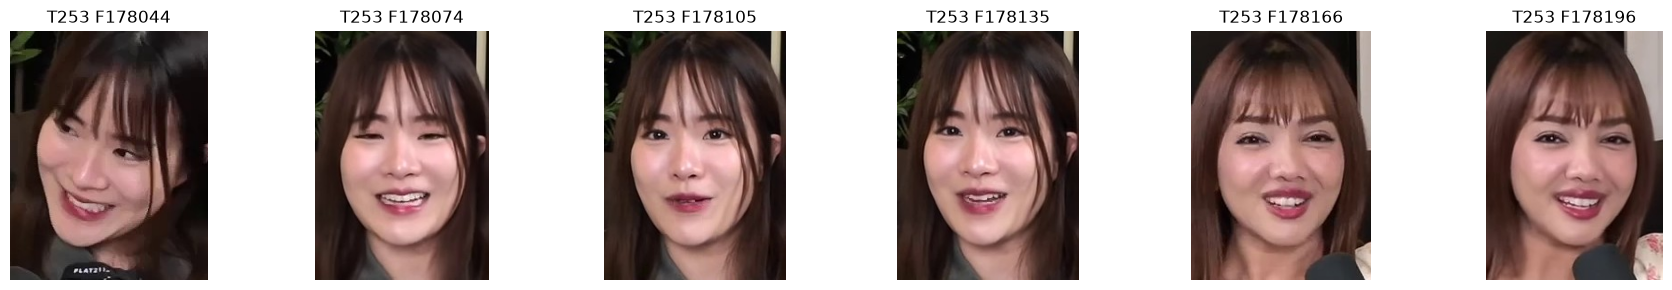

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

SAMPLE_META_CSV = REID_ROOT / "track_sample_metadata.csv"
sample_meta_df = pd.read_csv(SAMPLE_META_CSV)
sample_meta_df["track_id"] = sample_meta_df["track_id"].astype(int)

review_tracks = (
    final_map_df[
        final_map_df["status"] == "REVIEW"
    ]["track_id"]
    .astype(int)
    .tolist()
)

print("REVIEW tracks:", review_tracks)

MAX_REVIEW_TRACKS_TO_SHOW = 20

for tid in review_tracks[:MAX_REVIEW_TRACKS_TO_SHOW]:
    row = final_map_df[
        final_map_df["track_id"] == tid
    ].iloc[0]

    samples = sample_meta_df[
        sample_meta_df["track_id"] == tid
    ].head(6)

    print(
        f"\nTrack {tid} | "
        f"candidate={int(row['candidate_speaker_id'])} | "
        f"sim0={row['sim_speaker0']:.3f} | "
        f"sim1={row['sim_speaker1']:.3f} | "
        f"margin={row['similarity_margin']:.3f}"
    )

    if len(samples) == 0:
        continue

    fig, axes = plt.subplots(
        1,
        len(samples),
        figsize=(3 * len(samples), 3)
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, (_, srow) in zip(axes, samples.iterrows()):
        img_path = PROJECT_ROOT / srow["sample_path"]
        img = Image.open(img_path)

        ax.imshow(img)
        ax.set_title(
            f"T{tid} F{int(srow['frame_index'])}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Cell 13 — Save final map

In [13]:
FINAL_MAP_CSV = OUTPUT_ROOT / "final_track_speaker_map.csv"
AUTO_MAP_CSV = OUTPUT_ROOT / "final_track_speaker_map_auto.csv"
REVIEW_MAP_CSV = OUTPUT_ROOT / "final_track_speaker_map_review.csv"

final_map_df.to_csv(
    FINAL_MAP_CSV,
    index=False,
    encoding="utf-8-sig"
)

final_map_df[
    final_map_df["status"] == "AUTO"
].to_csv(
    AUTO_MAP_CSV,
    index=False,
    encoding="utf-8-sig"
)

final_map_df[
    final_map_df["status"] == "REVIEW"
].to_csv(
    REVIEW_MAP_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(" -", FINAL_MAP_CSV)
print(" -", AUTO_MAP_CSV)
print(" -", REVIEW_MAP_CSV)

Saved:
 - D:\Face_detection\dataset\reid\video001\final_2speaker\final_track_speaker_map.csv
 - D:\Face_detection\dataset\reid\video001\final_2speaker\final_track_speaker_map_auto.csv
 - D:\Face_detection\dataset\reid\video001\final_2speaker\final_track_speaker_map_review.csv


## Cell 14 — เพิ่ม speaker_id กลับเข้า detection data

In [14]:
final_detection_df = reid_df.drop(
    columns=["speaker_id"],
    errors="ignore"
).merge(
    final_map_df[
        [
            "track_id",
            "speaker_id",
            "status",
            "sim_speaker0",
            "sim_speaker1",
            "similarity_margin",
        ]
    ],
    on="track_id",
    how="left"
)

FINAL_DETECTION_CSV = OUTPUT_ROOT / "final_2speaker_detection.csv"

final_detection_df.to_csv(
    FINAL_DETECTION_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Rows:", len(final_detection_df))
print(
    "Speaker IDs:",
    sorted(
        final_detection_df["speaker_id"]
        .dropna()
        .unique()
        .tolist()
    )
)
print(
    "AUTO rows:",
    int((final_detection_df["status"] == "AUTO").sum())
)
print(
    "REVIEW rows:",
    int((final_detection_df["status"] == "REVIEW").sum())
)
print("Saved:", FINAL_DETECTION_CSV)

Rows: 256620
Speaker IDs: [0.0, 1.0]
AUTO rows: 256152
REVIEW rows: 265
Saved: D:\Face_detection\dataset\reid\video001\final_2speaker\final_2speaker_detection.csv


## Cell 15 — Final speaker summary

In [15]:
speaker_summary = (
    final_detection_df[
        final_detection_df["speaker_id"].notna()
    ]
    .groupby("speaker_id")
    .agg(
        detections=("frame_index", "count"),
        tracks=("track_id", "nunique"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        mean_conf=("det_score", "mean"),
    )
    .reset_index()
)

display(speaker_summary)

,speaker_id,detections,tracks,first_frame,last_frame,mean_conf
0,0.0,118277,117,0,178333,0.826957
1,1.0,137875,132,0,178333,0.815844


# ขั้นต่อไป

ถ้า QA ผ่าน ให้ใช้:

`dataset/reid/video001/final_2speaker/final_2speaker_detection.csv`

แทน detection.csv เดิมใน Mouth Extraction

จากนั้น Mouth Extraction จะจัดข้อมูลตาม:

```text
speaker_000/
speaker_001/
```

และข้าม track ที่ `REVIEW` เพื่อรักษาคุณภาพ dataset